# rasterio: datos raster

[![Abrir en Google Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/gf0657-programacionsig/2026-ii/blob/main/contenidos/iv-procesamiento-datos-geoespaciales/19-rasterio-datos-raster.ipynb)

## Trabajo previo

### Lecturas

Antes de la clase, revise las siguientes lecturas, en inglés. La guía de inicio rápido de la documentación oficial recorre, en pocas páginas, las operaciones de este cuaderno: abrir un archivo, consultar sus metadatos, leer la matriz y escribir un archivo nuevo. La sección del libro de Dorman et al. presenta el modelo raster desde Python, con los mismos objetos de rasterio y numpy.

Rasterio Contributors. (s. f.). Python quickstart. En *Rasterio documentation*. Recuperado el 18 de octubre de 2026, de https://rasterio.readthedocs.io/en/stable/quickstart.html
\
\
Dorman, M., Graser, A., Nowosad, J. y Lovelace, R. (2025). Raster data. En *Geocomputation with Python* (sección 1.3). CRC Press. https://py.geocompx.org/01-spatial-data#sec-raster-data

### Otros recursos

En la documentación de rasterio, las páginas sobre [ventanas de lectura](https://rasterio.readthedocs.io/en/stable/topics/windowed-rw.html), [enmascaramiento con geometrías](https://rasterio.readthedocs.io/en/stable/topics/masking-by-shapefile.html) y [reproyección](https://rasterio.readthedocs.io/en/stable/topics/reproject.html) amplían las secciones correspondientes de este cuaderno. El capítulo [Raster-vector interactions](https://py.geocompx.org/05-raster-vector) de Dorman et al. (2025) desarrolla el recorte, el enmascaramiento y las estadísticas zonales. La [guía del usuario de numpy](https://numpy.org/doc/stable/user/index.html) es la referencia para las operaciones con matrices, que son la base de todo lo que sigue.

## Introducción

Los dos cuadernos anteriores trabajaron con el **modelo vectorial**: puntos, líneas y polígonos con atributos. La [lección 16](https://gf0657-programacionsig.github.io/2026-ii/datos-geoespaciales/) presentó el otro modelo, el **raster**: una matriz de celdas del mismo tamaño, cada una con un valor, y un encabezado que dice dónde está la matriz sobre la Tierra. Es la representación natural de los fenómenos **continuos**, que tienen un valor en todo punto del territorio (altitud, temperatura, precipitación) y de las **imágenes** de satélite, que son matrices de reflectancia, una por banda del espectro.

[rasterio](https://rasterio.readthedocs.io/) es la biblioteca de Python para leer y escribir datos raster. Como geopandas, se apoya en [GDAL](https://gdal.org/): abre los mismos formatos que QGIS (GeoTIFF en primer lugar), pero entrega la matriz como un *array* de [numpy](https://numpy.org/), la biblioteca de cálculo numérico sobre la que se construyen pandas, geopandas y casi toda la ciencia de datos en Python. Esa es la idea central del cuaderno: un raster es **una matriz de numpy más un encabezado**. rasterio se encarga del encabezado (el SRC, el origen, la resolución, el valor que marca las celdas sin dato) y de la correspondencia entre las celdas y las coordenadas; todo lo demás, estadísticas, álgebra de mapas, clasificación, índices espectrales, es numpy.

Los datos son de dos fuentes. [WorldClim](https://www.worldclim.org/), versión 2.1, publica rasters mundiales de clima promedio del periodo 1970-2000 y de altitud; se usan aquí a 10 minutos de arco de resolución (celdas de unos 18 km en el ecuador), la misma escala mundial de los países de Natural Earth de los cuadernos anteriores, y la altitud de Centroamérica a 2,5 minutos (unos 4,6 km). Y una imagen del satélite [Sentinel-2](https://www.esa.int/Applications/Observing_the_Earth/Copernicus/Sentinel-2) del programa Copernicus de la Unión Europea, con cuatro bandas de 10 m de resolución sobre el [Refugio Nacional de Vida Silvestre Gandoca-Manzanillo](https://es.wikipedia.org/wiki/Refugio_nacional_de_vida_silvestre_mixto_Jairo_Mora_Sandoval_Gandoca-Manzanillo), en el Caribe sur de Costa Rica, obtenida del catálogo abierto de [Microsoft Planetary Computer](https://planetarycomputer.microsoft.com/). Los archivos están en los directorios [`datos/worldclim/`](https://github.com/gf0657-programacionsig/2026-ii/tree/main/datos/worldclim) y [`datos/sentinel/`](https://github.com/gf0657-programacionsig/2026-ii/tree/main/datos/sentinel) del repositorio del curso, con los programas que los prepararon, y se complementan con los países y ciudades de [Natural Earth](https://www.naturalearthdata.com/) de la parte vectorial.

Como todos los cuadernos del curso, puede ejecutarse en la nube, con la insignia "Abrir en Google Colab", o localmente, en [Visual Studio Code](https://gf0657-programacionsig.github.io/2026-ii/vscode/) con el ambiente `geopython` como kernel. Colab trae rasterio y geopandas instalados. El archivo `.ipynb` puede descargarse con el botón de descarga (ícono de flecha hacia abajo) en la parte superior de la página del cuaderno, en el sitio web del curso.

In [1]:
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import rasterio
from rasterio.plot import show

# Direcciones de los directorios de datos en el repositorio del curso
DATOS_WC = "https://raw.githubusercontent.com/gf0657-programacionsig/2026-ii/main/datos/worldclim"
DATOS_S2 = "https://raw.githubusercontent.com/gf0657-programacionsig/2026-ii/main/datos/sentinel"
DATOS_NE = "https://raw.githubusercontent.com/gf0657-programacionsig/2026-ii/main/datos/natural-earth"

# Colores de los cuadernos anteriores
AZUL = "#1F77B4"
NARANJA = "#D97B1B"

print("rasterio", rasterio.__version__)
print("numpy", np.__version__)

rasterio 1.5.1
numpy 2.5.1


## Apertura de un raster y sus metadatos

`rasterio.open()` abre un archivo raster, local o remoto (como `gpd.read_file()`, lee directamente de una URL), y retorna un objeto que representa el **conjunto de datos** (*dataset*): todavía no ha leído la matriz, solo el encabezado. La capa de altitud de WorldClim:

In [2]:
# Apertura de la capa de altitud (lectura directa desde la URL, como con geopandas)
altitud = rasterio.open(f"{DATOS_WC}/altitud.tif")
altitud

<open DatasetReader name='https://raw.githubusercontent.com/gf0657-programacionsig/2026-ii/main/datos/worldclim/altitud.tif' mode='r'>

Los atributos del objeto describen el raster. Los primeros dicen cuántas matrices hay y de qué tamaño y tipo:

In [3]:
# Estructura: bandas, dimensiones y tipo de dato
print("Bandas:", altitud.count)
print("Columnas (ancho):", altitud.width)
print("Filas (alto):", altitud.height)
print("Forma (filas, columnas):", altitud.shape)
print("Tipo de dato por banda:", altitud.dtypes)

Bandas: 1
Columnas (ancho): 2160
Filas (alto): 1080
Forma (filas, columnas): (1080, 2160)
Tipo de dato por banda: ('int16',)


Una sola **banda** (una sola matriz; una imagen de satélite tiene varias), de 2 160 columnas por 1 080 filas, con valores enteros de 16 bits (`int16`, de −32 768 a 32 767: suficiente para metros de altitud y la mitad de espacio que un flotante). Los atributos siguientes son los que sitúan la matriz sobre la Tierra:

In [4]:
# Georreferenciación: SRC, resolución, límites y valor sin dato
print("SRC:", altitud.crs)
print("Resolución (ancho, alto de la celda):", altitud.res)
print("Límites:", altitud.bounds)
print("Valor sin dato:", altitud.nodata)

SRC: EPSG:4326
Resolución (ancho, alto de la celda): (0.16666666666666666, 0.16666666666666666)
Límites: BoundingBox(left=-180.0, bottom=-90.0, right=180.0, top=90.0)
Valor sin dato: -32768.0


El SRC es WGS84 (EPSG:4326), así que la resolución está en grados: 1/6 de grado, los 10 minutos de arco de la fuente. Los límites cubren el mundo entero. Y el **valor sin dato** (`nodata`), −32 768, es el que ocupa las celdas donde no hay información, aquí el océano: es un valor cualquiera del tipo de dato, elegido por quien produjo el archivo, y hay que tratarlo como tal (se verá en seguida).

Los límites y la resolución se resumen en la **transformación afín** (`transform`), el verdadero encabezado del raster: seis números que convierten índices de la matriz (fila, columna) en coordenadas (x, y) y viceversa. Sus elementos son el ancho de la celda, el alto (negativo, porque las filas crecen hacia abajo y las latitudes hacia arriba) y las coordenadas del **origen**, la esquina superior izquierda de la matriz:

In [5]:
# Transformación afín: resolución en x, rotación, origen x; rotación, resolución en y, origen y
altitud.transform

Affine(0.16666666666666666, 0.0, -180.0,
       0.0, -0.16666666666666666, 90.0)

La figura 1 muestra la relación. Cada celda tiene un **índice** (fila, columna), que empieza en 0 en la esquina superior izquierda, como cualquier matriz, y unas **coordenadas** en el SRC, que la transformación calcula: `x = origen_x + columna × ancho` e `y = origen_y − fila × alto`. Este doble sistema, índices de matriz y coordenadas geográficas, recorre todo el cuaderno.

<figure style="text-align: center;">
  <img
    src="https://raw.githubusercontent.com/gf0657-programacionsig/2026-ii/main/contenidos/iv-procesamiento-datos-geoespaciales/img/raster-indices-coordenadas.png"
    alt="Matriz de un raster con sus índices de fila y columna y las coordenadas de sus celdas"
    width="760"
  >
  <figcaption><strong>Figura 1</strong>. Índices y coordenadas de un raster: la matriz se indexa por (fila, columna) desde la esquina superior izquierda, y la transformación afín (origen y resolución) asigna a cada celda sus coordenadas en el SRC. Fuente: elaboración propia.</figcaption>
</figure>

Todo el encabezado junto está en `profile`, un diccionario que, como se verá en la sección de escritura, sirve de plantilla para crear archivos nuevos. Las bandas pueden tener una descripción y el archivo, etiquetas de texto libre:

In [6]:
# Perfil completo, descripciones de las bandas y etiquetas
print(altitud.profile)
print(altitud.descriptions)
print(altitud.tags())

{'driver': 'GTiff', 'dtype': 'int16', 'nodata': -32768.0, 'width': 2160, 'height': 1080, 'count': 1, 'crs': CRS.from_wkt('GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AXIS["Latitude",NORTH],AXIS["Longitude",EAST],AUTHORITY["EPSG","4326"]]'), 'transform': Affine(0.16666666666666666, 0.0, -180.0,
       0.0, -0.16666666666666666, 90.0), 'blockxsize': 2160, 'blockysize': 1, 'tiled': False, 'compress': 'lzw', 'interleave': 'band'}
('Altitud (m)',)
{'AREA_OR_POINT': 'Area'}


El objeto que retorna `rasterio.open()` mantiene el archivo abierto. En programas que abren muchos archivos conviene usarlo con `with`, que lo cierra al salir del bloque, como con los archivos de texto; en un cuaderno, donde el mismo raster se consulta en muchas celdas, es cómodo dejarlo abierto, como aquí. Las otras capas de WorldClim se abren igual:

In [7]:
# Temperatura media anual (°C) y precipitación anual (mm), mismas dimensiones y SRC que la altitud
temperatura = rasterio.open(f"{DATOS_WC}/temperatura.tif")
precipitacion = rasterio.open(f"{DATOS_WC}/precipitacion.tif")

for capa in [altitud, temperatura, precipitacion]:
    print(capa.descriptions[0], "|", capa.shape, "|", capa.dtypes[0], "| sin dato:", capa.nodata)

Altitud (m) | (1080, 2160) | int16 | sin dato: -32768.0
Temperatura media anual 1970-2000 (°C) | (1080, 2160) | float32 | sin dato: -3.3999999521443642e+38
Precipitación anual 1970-2000 (mm) | (1080, 2160) | int16 | sin dato: -32768.0


Las tres capas están **alineadas**: mismas dimensiones, mismo SRC, misma transformación. Es la condición para operar entre ellas celda a celda, como se hará en el álgebra de mapas. La temperatura es de tipo flotante, y su valor sin dato es el número negativo más grande que cabe en 32 bits, otra convención frecuente.

*Ejercicios de esta sección: 1, en la sección de ejercicios al final del cuaderno.*

## La matriz de celdas: numpy

`read()` lee la matriz. Con el número de la banda (empiezan en 1, no en 0), retorna un **array de numpy** de dos dimensiones, filas por columnas:

In [8]:
# Lectura de la banda 1 como array de numpy
matriz = altitud.read(1)

print(type(matriz))
print("Forma:", matriz.shape)
print("Tipo:", matriz.dtype)
print("Valor mínimo:", matriz.min())
matriz

<class 'numpy.ndarray'>
Forma: (1080, 2160)
Tipo: int16
Valor mínimo: -32768


array([[-32768, -32768, -32768, ..., -32768, -32768, -32768],
       [-32768, -32768, -32768, ..., -32768, -32768, -32768],
       [-32768, -32768, -32768, ..., -32768, -32768, -32768],
       ...,
       [  2731,   2874,   2873, ...,   2876,   2875,   2587],
       [  2654,   2794,   2793, ...,   2794,   2794,   2514],
       [  2502,   2634,   2634, ...,   2634,   2634,   2371]],
      shape=(1080, 2160), dtype=int16)

El mínimo es −32 768: el valor sin dato del océano, que numpy toma como un número más. Cualquier estadística calculada sobre esta matriz sería incorrecta, y sin ningún error que lo advierta. Es el error más frecuente con datos raster, y la solución es leer con `masked=True`, que retorna un **array enmascarado** (`numpy.ma.MaskedArray`): la matriz más una máscara booleana que marca las celdas sin dato, y que las operaciones de numpy respetan:

In [9]:
# Lectura con máscara: las celdas sin dato quedan excluidas de los cálculos
altitud_m = altitud.read(1, masked=True)

print(type(altitud_m))
print("Celdas en total:", altitud_m.size)
print("Celdas con dato:", altitud_m.count())
print("Proporción con dato:", round(altitud_m.count() / altitud_m.size, 3))
print("Mínimo:", altitud_m.min(), "| máximo:", altitud_m.max(), "| media:", round(float(altitud_m.mean()), 1))

<class 'numpy.ma.MaskedArray'>
Celdas en total: 2332800
Celdas con dato: 808053
Proporción con dato: 0.346
Mínimo: -352 | máximo: 6251 | media: 1088.6


Un tercio de las celdas tiene dato (la tierra firme, incluida la Antártida); el resto es océano. Las estadísticas ya tienen sentido: la celda más alta, 6 251 m, es un promedio de 18 km sobre el Himalaya, no la cima del Everest.

Un array de numpy se opera como un todo. Las comparaciones producen matrices booleanas, cuya suma cuenta las celdas que cumplen la condición; las funciones estadísticas de numpy aceptan arrays enmascarados, y `compressed()` extrae los valores con dato como un vector plano, útil para percentiles e histogramas:

In [10]:
# Operaciones vectorizadas: comparación, conteo y percentiles
muy_altas = altitud_m > 4000
print("Celdas por encima de 4 000 m:", muy_altas.sum(), "(", round(float(muy_altas.sum() / altitud_m.count() * 100), 2), "% de la tierra firme)")

valores = altitud_m.compressed()
print("Percentiles 25, 50, 75 y 90 de la altitud (m):", np.percentile(valores, [25, 50, 75, 90]))

Celdas por encima de 4 000 m: 9318 ( 1.15 % de la tierra firme)
Percentiles 25, 50, 75 y 90 de la altitud (m): [ 193.  554. 1822. 2960.]


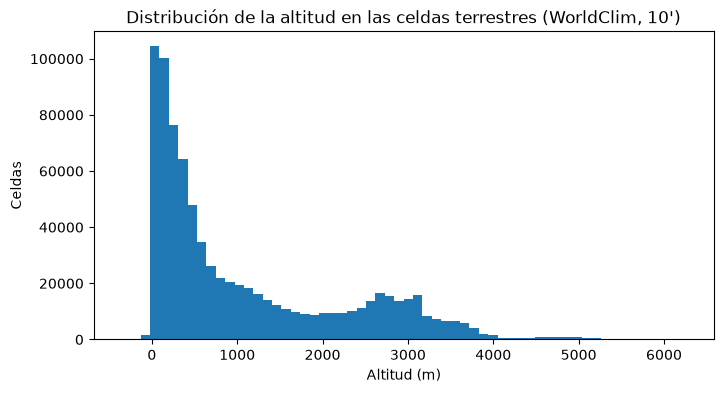

In [11]:
# Histograma de la altitud de las celdas con dato
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(valores, bins=60, color=AZUL)
ax.set_xlabel("Altitud (m)")
ax.set_ylabel("Celdas")
ax.set_title("Distribución de la altitud en las celdas terrestres (WorldClim, 10')")
plt.show()

La mitad de las celdas terrestres está por debajo de 554 m y una de cada diez por encima de 2 960 m. Una advertencia para este tipo de conteos: en una cuadrícula en grados, las celdas no tienen la misma área (se estrechan hacia los polos), de modo que contar celdas no equivale a medir superficie. La sección de reproyección vuelve sobre esto.

*Ejercicios de esta sección: 2, en la sección de ejercicios al final del cuaderno.*

## Graficación

`show()`, del módulo `rasterio.plot`, dibuja un raster con los ejes en coordenadas del SRC, a partir del conjunto de datos abierto o de un array más su transformación:

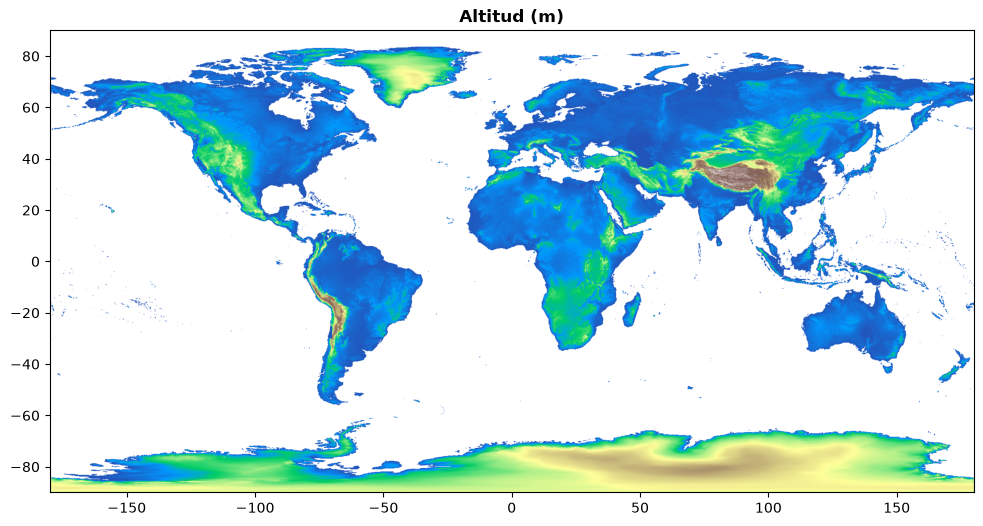

In [12]:
# Mapa de la altitud con show() de rasterio
fig, ax = plt.subplots(figsize=(12, 6))
show(altitud, ax=ax, cmap="terrain", title="Altitud (m)")
plt.show()

Las celdas sin dato se dibujan con el valor −32 768, que arrastra la escala de colores: por eso el océano aparece oscuro y la tierra firme, aplastada en el extremo de la paleta. Para un mapa cuidado conviene usar directamente `imshow()` de matplotlib con el array enmascarado (las celdas enmascaradas quedan transparentes), el argumento `extent` con los límites del raster para que los ejes estén en coordenadas, y una barra de color. Y, como con cualquier `Axes`, encima se dibujan capas vectoriales en el mismo SRC, aquí los límites de los países de Natural Earth:

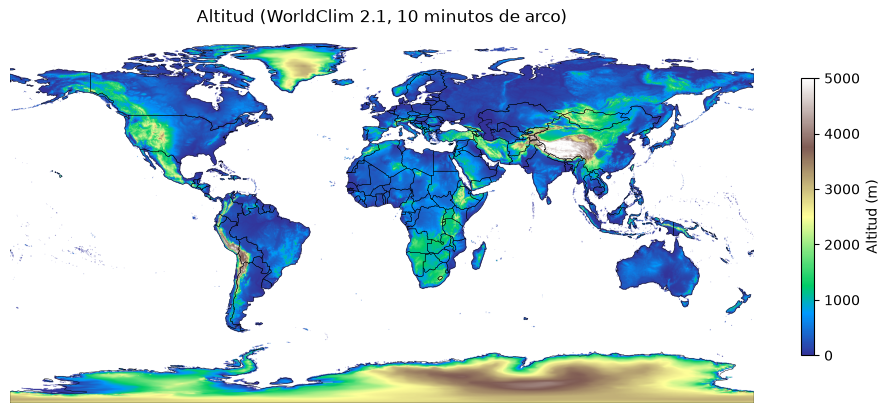

In [13]:
# Países de Natural Earth (WGS84, como los rasters)
paises = gpd.read_file(f"{DATOS_NE}/paises.gpkg")

# Mapa de la altitud con imshow(): array enmascarado, extent en coordenadas y barra de color
limites = [altitud.bounds.left, altitud.bounds.right, altitud.bounds.bottom, altitud.bounds.top]

fig, ax = plt.subplots(figsize=(12, 6))
imagen = ax.imshow(altitud_m, cmap="terrain", extent=limites, vmin=0, vmax=5000)
paises.boundary.plot(ax=ax, color="black", linewidth=0.3)
fig.colorbar(imagen, ax=ax, shrink=0.6, label="Altitud (m)")
ax.set_title("Altitud (WorldClim 2.1, 10 minutos de arco)")
ax.set_axis_off()
plt.show()

La elección de la **paleta de colores** (`cmap`) sigue las reglas del cuaderno de matplotlib: secuencial para magnitudes (`terrain` y `YlGn` para la altitud, `Blues` para la precipitación), divergente para variables con un centro significativo (la temperatura alrededor de 0 °C, con `RdBu_r`). Los límites `vmin` y `vmax` fijan el rango de la escala, lo que evita que unos pocos valores extremos la dominen. Las tres variables de WorldClim, una junto a otra:

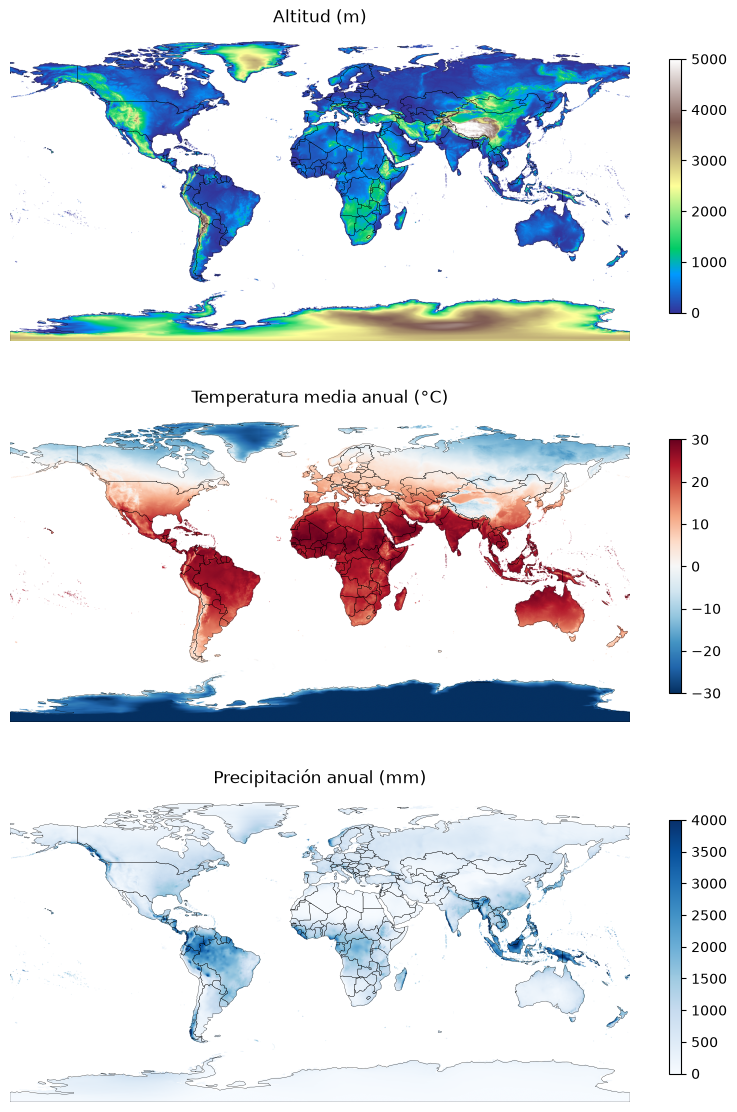

In [14]:
# Las tres capas de WorldClim en un panel
temperatura_m = temperatura.read(1, masked=True).astype("float64")  # en 64 bits: el valor sin dato de 32 bits desborda al escalar los colores
precipitacion_m = precipitacion.read(1, masked=True)

paneles = [
    (altitud_m, "terrain", 0, 5000, "Altitud (m)"),
    (temperatura_m, "RdBu_r", -30, 30, "Temperatura media anual (°C)"),
    (precipitacion_m, "Blues", 0, 4000, "Precipitación anual (mm)"),
]

fig, ejes = plt.subplots(3, 1, figsize=(10, 14))
for ax, (capa, paleta, minimo, maximo, titulo) in zip(ejes, paneles):
    imagen = ax.imshow(capa, cmap=paleta, extent=limites, vmin=minimo, vmax=maximo)
    paises.boundary.plot(ax=ax, color="black", linewidth=0.2)
    fig.colorbar(imagen, ax=ax, shrink=0.8)
    ax.set_title(titulo)
    ax.set_axis_off()
plt.show()

A escala mundial, 10 minutos de arco bastan. Para una región pequeña no: la **resolución** determina qué se puede ver. La altitud de Centroamérica a 10 minutos y a 2,5 minutos (16 veces más celdas por la misma superficie), con la capa regional de países:

In [15]:
# Altitud de Centroamérica a 2,5 minutos de arco (unos 4,6 km) y la capa regional de países
altitud_ca = rasterio.open(f"{DATOS_WC}/altitud-centroamerica.tif")
centroamerica = gpd.read_file(f"{DATOS_NE}/centroamerica.gpkg")

print("Resolución:", altitud_ca.res, "| forma:", altitud_ca.shape, "| límites:", altitud_ca.bounds)

Resolución: (0.041666666666666664, 0.041666666666666664) | forma: (288, 384) | límites: BoundingBox(left=-93.0, bottom=7.0, right=-77.0, top=19.0)


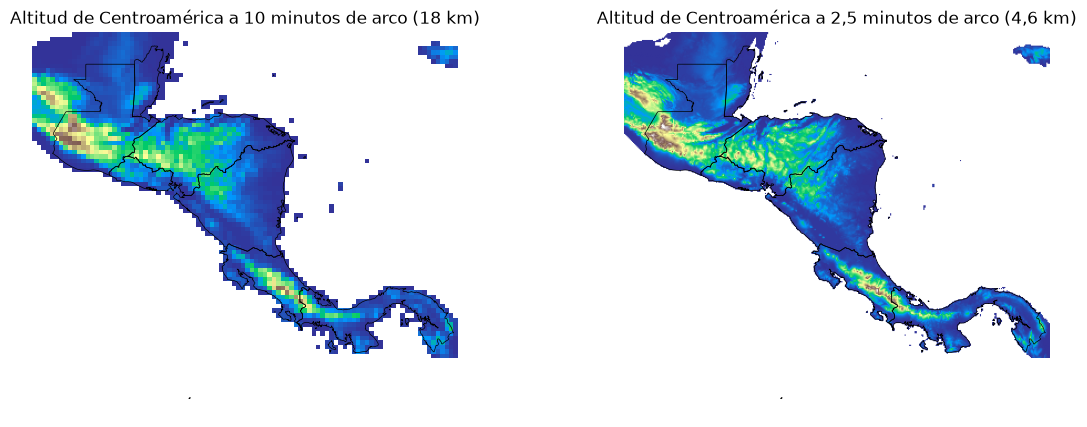

In [16]:
# La misma región a dos resoluciones: ventana de la capa mundial frente a la capa regional
from rasterio.windows import from_bounds

# Ventana de lectura de la capa mundial con los límites de la capa regional
ventana = from_bounds(*altitud_ca.bounds, transform=altitud.transform)
altitud_ca_10 = altitud.read(1, window=ventana, masked=True)
limites_ca = [altitud_ca.bounds.left, altitud_ca.bounds.right, altitud_ca.bounds.bottom, altitud_ca.bounds.top]

fig, ejes = plt.subplots(1, 2, figsize=(14, 5))
for ax, capa, titulo in zip(ejes, [altitud_ca_10, altitud_ca.read(1, masked=True)], ["10 minutos de arco (18 km)", "2,5 minutos de arco (4,6 km)"]):
    ax.imshow(capa, cmap="terrain", extent=limites_ca, vmin=0, vmax=3500)
    centroamerica.boundary.plot(ax=ax, color="black", linewidth=0.5)
    ax.set_title(f"Altitud de Centroamérica a {titulo}")
    ax.set_axis_off()
plt.show()

La **ventana** (`Window`) es la forma de leer solo una parte de un raster: `from_bounds()` la construye a partir de unos límites en coordenadas, y `read(window=...)` lee únicamente esas filas y columnas. Con rasters grandes (una imagen de satélite completa pesa gigabytes) es la diferencia entre poder trabajar o no; además, como GDAL lee por internet solo los bloques que la ventana necesita, es también la forma de consultar un raster remoto sin descargarlo entero (así se prepararon la capa regional y la imagen Sentinel-2 de este cuaderno).

*Ejercicios de esta sección: 3, en la sección de ejercicios al final del cuaderno.*

## Celdas y coordenadas

La transformación afín convierte en ambas direcciones. Como objeto de Python, se multiplica por un par (columna, fila) y retorna las coordenadas de la **esquina superior izquierda** de esa celda; su inversa, `~transform`, convierte coordenadas en (columna, fila), con decimales:

In [17]:
# De índices a coordenadas y de coordenadas a índices (columna, fila) con la transformación afín
print("Esquina de la celda (0, 0):", altitud.transform * (0, 0))
print("Esquina de la celda (columna 575, fila 480):", altitud.transform * (575, 480))
print("Columna y fila de San José (longitud −84,08, latitud 9,93):", ~altitud.transform * (-84.08, 9.93))

Esquina de la celda (0, 0): (-180.0, 90.0)
Esquina de la celda (columna 575, fila 480): (-84.16666666666667, 10.0)
Columna y fila de San José (longitud −84,08, latitud 9,93): (575.52, 480.42)


Dos métodos del conjunto de datos hacen lo mismo con el orden de la matriz, (fila, columna): `index()` recibe coordenadas (x, y, es decir, longitud y latitud, **en ese orden**, como siempre) y retorna la fila y la columna de la celda que las contiene, e `xy()` recibe fila y columna y retorna las coordenadas del **centro** de la celda. Con ellos se consulta el valor de un lugar:

In [18]:
# Altitud, temperatura y precipitación de la celda de San José
fila, columna = altitud.index(-84.08, 9.93)
print("Fila y columna:", fila, columna)
print("Centro de la celda:", tuple(round(c, 4) for c in altitud.xy(fila, columna)))
print("Altitud:", altitud_m[fila, columna], "m")
print("Temperatura media anual:", round(float(temperatura_m[fila, columna]), 1), "°C")
print("Precipitación anual:", precipitacion_m[fila, columna], "mm")

Fila y columna: 480 575
Centro de la celda: (np.float64(-84.0833), np.float64(9.9167))
Altitud: 1315 m
Temperatura media anual: 19.8 °C
Precipitación anual: 2930 mm


La celda de San José (18 km de lado, que abarcan desde el valle hasta las montañas vecinas) tiene una altitud media de 1 315 m, más que los 1 100 m de la ciudad: el valor de una celda es el promedio de su superficie, no el de un punto. Para muchos puntos a la vez, `sample()` recibe una secuencia de pares (x, y) y retorna el valor de cada uno (un array por punto, con un elemento por banda). Las ciudades de Natural Earth, con su altitud:

In [19]:
# Altitud de las 243 ciudades principales: muestreo del raster en sus coordenadas
ciudades = pd.read_csv(f"{DATOS_NE}/ciudades.csv")
coordenadas = list(zip(ciudades["longitud"], ciudades["latitud"]))
ciudades["altitud"] = [valor[0] for valor in altitud.sample(coordenadas)]

# Capitales más altas
ciudades[ciudades["capital"]].sort_values("altitud", ascending=False)[["nombre", "pais", "altitud"]].head(8)

,nombre,pais,altitud
122,La Paz,Bolivia,4415
88,Quito,Ecuador,3236
126,Thimphu,Bhutan,2958
230,Bogota,Colombia,2851
114,Sucre,Bolivia,2757
206,Addis Ababa,Ethiopia,2651
147,Sanaa,Yemen,2305
224,Mexico City,Mexico,2241


La Paz, Quito, Timbu y Bogotá encabezan la lista, como se espera. Una comprobación importante antes de usar estos valores: `sample()` retorna el valor sin dato, −32 768, para los puntos que caen en una celda vacía, sin aviso. Aquí ninguna ciudad cae en el océano, pero con rasters de menor cobertura (o puntos costeros) hay que filtrarlo. Y la otra regla, la de siempre: las coordenadas de los puntos deben estar en el **SRC del raster**; las ciudades vienen en WGS84, como WorldClim, y por eso no hubo que reproyectar.

*Ejercicios de esta sección: 4, en la sección de ejercicios al final del cuaderno.*

## Álgebra de mapas

El **álgebra de mapas** es el conjunto de operaciones que producen un raster nuevo a partir de uno o varios rasters alineados. Las más comunes son las **operaciones locales**, que calculan cada celda del resultado a partir de las mismas celdas de las entradas: en numpy, son simplemente operaciones aritméticas y lógicas entre arrays, que se aplican celda a celda.

Un ejemplo con dos capas: el [índice de aridez de De Martonne](https://es.wikipedia.org/wiki/%C3%8Dndice_de_aridez), `P / (T + 10)`, con la precipitación anual en mm y la temperatura media en °C, que clasifica los climas de árido (menos de 10) a húmedo (más de 30). Las celdas sin dato se propagan por la máscara, y las que no tienen sentido para la fórmula (temperaturas por debajo de −10 °C, donde el denominador se anula) se enmascaran con `np.ma.masked_where()`:

Celdas con índice: 503939
Proporción de celdas áridas (índice < 10): 18.1 %


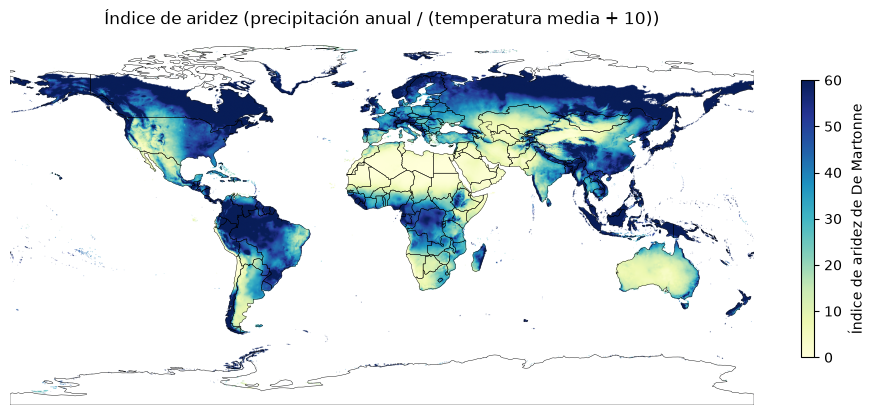

In [20]:
# Operación local entre dos capas: índice de aridez de De Martonne
aridez = precipitacion_m / (temperatura_m + 10)
aridez = np.ma.masked_where(temperatura_m <= -10, aridez)

print("Celdas con índice:", aridez.count())
print("Proporción de celdas áridas (índice < 10):", round(float((aridez < 10).sum() / aridez.count() * 100), 1), "%")

fig, ax = plt.subplots(figsize=(12, 6))
imagen = ax.imshow(aridez, cmap="YlGnBu", extent=limites, vmin=0, vmax=60)
paises.boundary.plot(ax=ax, color="black", linewidth=0.3)
fig.colorbar(imagen, ax=ax, shrink=0.6, label="Índice de aridez de De Martonne")
ax.set_title("Índice de aridez (precipitación anual / (temperatura media + 10))")
ax.set_axis_off()
plt.show()

La **reclasificación** convierte un raster continuo en uno **categórico**: a cada rango de valores se le asigna una clase. `np.digitize()` lo hace con una lista de umbrales y retorna, para cada celda, el número del intervalo en que cae. Los pisos altitudinales, en cuatro clases:

In [21]:
# Reclasificación de la altitud en pisos altitudinales (0: < 500 m, 1: 500-1 500, 2: 1 500-3 000, 3: > 3 000)
umbrales = [500, 1500, 3000]
pisos = np.digitize(altitud_m, umbrales)
pisos = np.ma.masked_array(pisos, mask=altitud_m.mask)

etiquetas = ["Tierras bajas (< 500 m)", "Premontano (500-1 500 m)", "Montano (1 500-3 000 m)", "Altoandino (> 3 000 m)"]
for clase, etiqueta in enumerate(etiquetas):
    print(f"{etiqueta}: {(pisos == clase).sum()} celdas")

Tierras bajas (< 500 m): 384133 celdas
Premontano (500-1 500 m): 192141 celdas
Montano (1 500-3 000 m): 156029 celdas
Altoandino (> 3 000 m): 75750 celdas


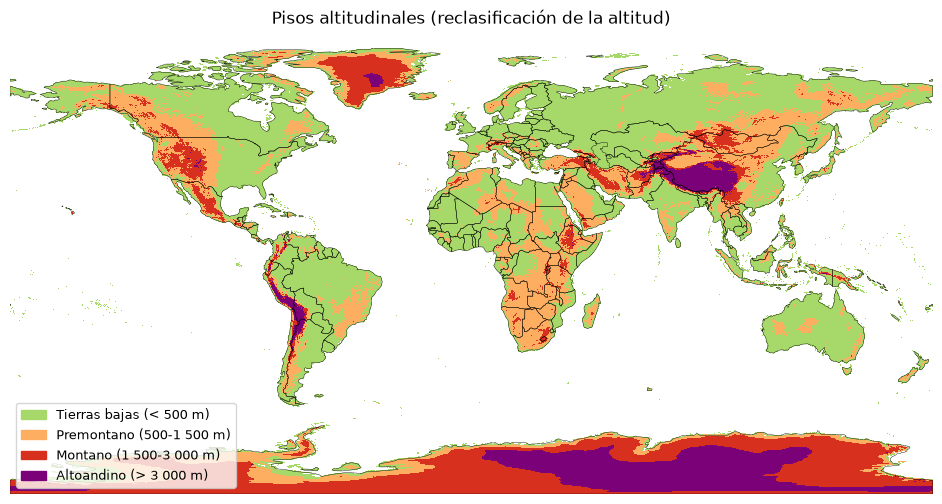

In [22]:
# Mapa del raster categórico: paleta discreta y leyenda con parches
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

colores = ["#A6D96A", "#FDAE61", "#D7301F", "#7A0177"]
paleta = ListedColormap(colores)

fig, ax = plt.subplots(figsize=(12, 6))
ax.imshow(pisos, cmap=paleta, extent=limites, vmin=-0.5, vmax=3.5, interpolation="nearest")
paises.boundary.plot(ax=ax, color="black", linewidth=0.3)
ax.legend(handles=[Patch(color=c, label=e) for c, e in zip(colores, etiquetas)], loc="lower left", fontsize=9)
ax.set_title("Pisos altitudinales (reclasificación de la altitud)")
ax.set_axis_off()
plt.show()

Dos detalles del mapa categórico: `vmin` y `vmax` a medio paso de los valores extremos, para que cada clase reciba exactamente uno de los colores de la paleta discreta, e `interpolation="nearest"`, para que matplotlib no mezcle colores entre celdas vecinas (con una paleta discreta, la mezcla produciría clases que no existen).

Las operaciones **lógicas** combinan condiciones sobre varias capas: la máscara booleana resultante selecciona celdas o cuenta cuántas cumplen la condición. Las celdas de clima tropical húmedo, con más de 25 °C y más de 2 000 mm:

In [23]:
# Operación lógica entre capas: celdas cálidas y lluviosas
tropico_humedo = (temperatura_m > 25) & (precipitacion_m > 2000)
print("Celdas de trópico húmedo:", tropico_humedo.sum(), "(", round(float(tropico_humedo.sum() / temperatura_m.count() * 100), 2), "% de la tierra firme)")
print("Altitud media de esas celdas:", round(float(altitud_m[tropico_humedo].mean())), "m")

Celdas de trópico húmedo: 25272 ( 3.13 % de la tierra firme)
Altitud media de esas celdas: 126 m


Hay otras familias de operaciones del álgebra de mapas: las **focales**, que calculan cada celda a partir de sus vecinas (suavizado, pendiente a partir de la altitud), y las **zonales**, que resumen las celdas de cada zona definida por otra capa. Las focales se resuelven con filtros de [scipy](https://scipy.org/) o con [xarray-spatial](https://xarray-spatial.readthedocs.io/); las zonales son la siguiente sección.

*Ejercicios de esta sección: 5 y 6, en la sección de ejercicios al final del cuaderno.*

## Raster y vector: recorte, máscara y estadísticas zonales

Las preguntas más útiles combinan los dos modelos: ¿cuál es la altitud media de cada país? ¿cuánto llueve en una cuenca? La función `mask()` del módulo `rasterio.mask` recibe el conjunto de datos y una o más geometrías de shapely (o la columna de geometría de un GeoDataFrame) y retorna las celdas que caen dentro, con las de fuera puestas al valor sin dato; con `crop=True` recorta además la matriz a los límites de las geometrías. Las geometrías deben estar en el **SRC del raster**. La altitud de Brasil:

In [24]:
# Máscara y recorte de la altitud con el polígono de Brasil (geometrías en el SRC del raster)
from rasterio.mask import mask

brasil = paises[paises["nombre"] == "Brasil"]
print("SRC igual:", brasil.crs == altitud.crs)

recorte, transformacion = mask(altitud, brasil.geometry, crop=True)
altitud_brasil = np.ma.masked_equal(recorte[0], altitud.nodata)

print("Forma del recorte:", altitud_brasil.shape)
print("Celdas de Brasil:", altitud_brasil.count())
print("Altitud media:", round(float(altitud_brasil.mean())), "m | máxima:", altitud_brasil.max(), "m")
transformacion

SRC igual: True
Forma del recorte: (235, 236)
Celdas de Brasil: 25545
Altitud media: 326 m | máxima: 1600 m


Affine(0.16666666666666666, 0.0, -74.0,
       0.0, -0.16666666666666666, 5.333333333333343)

`mask()` retorna dos cosas: un array de **tres dimensiones** (bandas, filas, columnas), del que se toma la banda `[0]`, y la transformación afín del recorte, con el nuevo origen, que hace falta para dibujarlo o guardarlo. El array no viene enmascarado: `np.ma.masked_equal()` enmascara el valor sin dato. El recorte, con `show()` y su transformación:

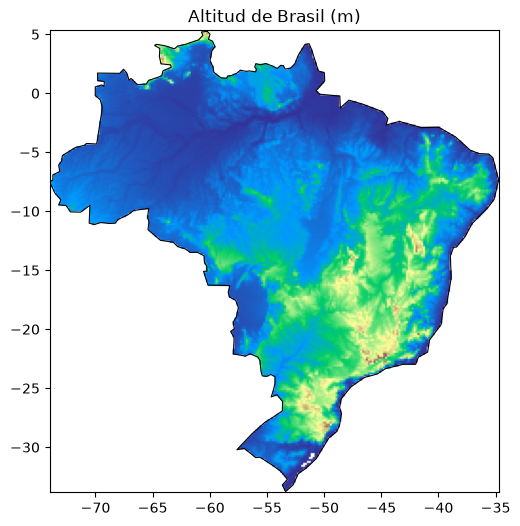

In [25]:
# Mapa del recorte: show() con el array y su transformación
fig, ax = plt.subplots(figsize=(7, 6))
show(altitud_brasil, transform=transformacion, ax=ax, cmap="terrain", vmin=0, vmax=2000)
brasil.boundary.plot(ax=ax, color="black", linewidth=0.8)
ax.set_title("Altitud de Brasil (m)")
plt.show()

Las **estadísticas zonales** repiten la operación para cada polígono de una capa: una máscara por país y un resumen de sus celdas. Con una comprensión de listas y un DataFrame de resultados, se unen después a la capa de países por el código, como se hizo con los indicadores del Banco Mundial:

In [26]:
# Estadísticas zonales: altitud, temperatura y precipitación medias de cada país
def media_zonal(capa, geometria):
    '''Media de las celdas de una capa dentro de una geometría (NaN si no hay celdas).'''
    recorte, _ = mask(capa, [geometria], crop=True)
    valores = np.ma.masked_equal(recorte[0], capa.nodata)
    return float(valores.mean()) if valores.count() > 0 else np.nan

zonales = pd.DataFrame({
    "codigo": paises["codigo"],
    "altitud_media": [media_zonal(altitud, g) for g in paises.geometry],
    "temperatura_media": [media_zonal(temperatura, g) for g in paises.geometry],
    "precipitacion_media": [media_zonal(precipitacion, g) for g in paises.geometry],
})

# Unión con la capa de países (el GeoDataFrame a la izquierda) y los países más altos
paises_clima = paises.merge(zonales, on="codigo")
paises_clima.sort_values("altitud_media", ascending=False)[["nombre", "altitud_media", "temperatura_media", "precipitacion_media"]].head(8).round(1)

,nombre,altitud_media,temperatura_media,precipitacion_media
104,Tayikistán,2958.5,2.9,472.4
100,Bután,2874.0,9.7,1283.0
105,Kirguistán,2641.7,0.5,425.3
159,Antártida,2375.0,-37.4,110.9
26,Lesoto,2167.6,11.9,746.2
101,Nepal,2124.6,14.1,1353.3
109,Armenia,1860.0,6.3,503.3
103,Afganistán,1832.3,11.8,300.4


Tayikistán, Bután y Kirguistán son los países más altos en promedio; la Antártida aparece entre ellos. Las medias por país son el puente entre los dos modelos: un atributo nuevo en la capa vectorial, calculado desde el raster, que se mapea como cualquier otro (en Equal Earth, como en los cuadernos anteriores):

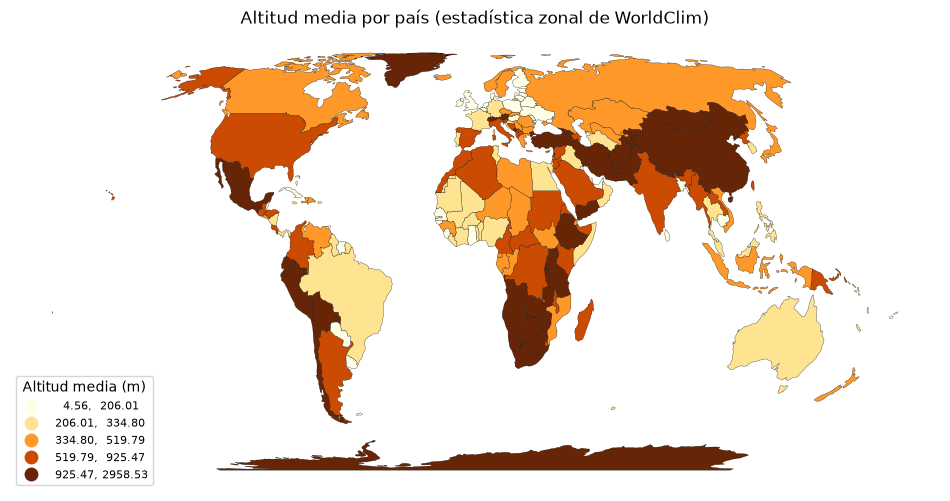

In [27]:
# Mapa de coropletas de la altitud media por país (requiere mapclassify)
fig, ax = plt.subplots(figsize=(12, 6))
paises_clima.to_crs(8857).plot(
    ax=ax, column="altitud_media", cmap="YlOrBr", scheme="quantiles", k=5,
    edgecolor="black", linewidth=0.2, legend=True,
    legend_kwds={"title": "Altitud media (m)", "loc": "lower left", "fontsize": 8},
)
ax.set_title("Altitud media por país (estadística zonal de WorldClim)")
ax.set_axis_off()
plt.show()

Dos advertencias. Los países muy pequeños pueden no contener el centro de ninguna celda a esta resolución, y la media queda vacía; `mask(..., all_touched=True)` incluye entonces toda celda que la geometría toque. Y, en una cuadrícula en grados, la media de las celdas de un país extenso en latitud pondera de más sus celdas del norte, que son más pequeñas: para estadísticas precisas se reproyecta antes a un SRC de igual área. Para hacer estadísticas zonales de forma rutinaria existe la biblioteca [rasterstats](https://pythonhosted.org/rasterstats/), que en una llamada calcula varias estadísticas por polígono.

*Ejercicios de esta sección: 7 y 8, en la sección de ejercicios al final del cuaderno.*

## Múltiples bandas: una imagen Sentinel-2

Una imagen de satélite es un raster de varias **bandas**: una matriz por intervalo del espectro electromagnético que el sensor mide. [Sentinel-2](https://www.esa.int/Applications/Observing_the_Earth/Copernicus/Sentinel-2) registra trece, cuatro de ellas a 10 m de resolución: azul, verde, roja e infrarroja cercana (NIR, *near infrared*). La imagen del refugio Gandoca-Manzanillo contiene esas cuatro, del 4 de febrero de 2024, un día con 7,5 % de nubes en la escena:

In [28]:
# Apertura de la imagen Sentinel-2 del refugio Gandoca-Manzanillo
gandoca = rasterio.open(f"{DATOS_S2}/gandoca-20240204.tif")

print("Bandas:", gandoca.count, gandoca.descriptions)
print("Forma:", gandoca.shape, "| tipo:", gandoca.dtypes[0], "| sin dato:", gandoca.nodata)
print("SRC:", gandoca.crs)
print("Resolución:", gandoca.res, "m")
print("Etiquetas:", gandoca.tags())

Bandas: 4 ('Azul (B02)', 'Verde (B03)', 'Roja (B04)', 'NIR (B08)')
Forma: (1231, 1811) | tipo: uint16 | sin dato: 0.0
SRC: EPSG:32617
Resolución: (10.0, 10.0) m
Etiquetas: {'escena': 'S2B_MSIL2A_20240204T160509_R054_T17PLL_20240204T213428', 'fecha': '2024-02-04', 'fuente': 'Microsoft Planetary Computer, Sentinel-2 L2A', 'AREA_OR_POINT': 'Area'}


El SRC es UTM zona 17 norte (EPSG:32617), el nativo de las escenas Sentinel-2 en Costa Rica, proyectado y en metros: cada celda mide 10 m × 10 m, y la imagen, 18 km × 12 km. Los valores son enteros sin signo (`uint16`), con el cero como valor sin dato.

`read()` sin argumentos lee todas las bandas en un array de **tres dimensiones**, (banda, fila, columna). Los valores de Sentinel-2 son reflectancias escaladas: la **reflectancia** (la fracción de la luz que la superficie refleja, entre 0 y 1) se obtiene restando 1 000 y dividiendo entre 10 000, según la convención de los productos actuales. La conversión se hace en flotante, con los valores sin dato enmascarados:

In [29]:
# Lectura de las cuatro bandas y conversión a reflectancia
bandas = gandoca.read(masked=True).astype("float32")
print("Forma del array (bandas, filas, columnas):", bandas.shape)

reflectancia = np.clip((bandas - 1000) / 10000, 0, 1)
azul, verde, rojo, nir = reflectancia

for nombre, banda in zip(gandoca.descriptions, reflectancia):
    print(f"{nombre}: media {float(banda.mean()):.3f}, percentiles 2 y 98: {np.percentile(banda.compressed(), [2, 98]).round(3)}")

Forma del array (bandas, filas, columnas): (4, 1231, 1811)
Azul (B02): media 0.028, percentiles 2 y 98: [0.011 0.058]
Verde (B03): media 0.038, percentiles 2 y 98: [0.018 0.077]
Roja (B04): media 0.019, percentiles 2 y 98: [0.005 0.069]
NIR (B08): media 0.219, percentiles 2 y 98: [0.002 0.433]


Una **composición en color** muestra tres bandas a la vez en los canales rojo, verde y azul de la pantalla. Con las bandas roja, verde y azul de la imagen se obtiene el **color verdadero**, lo que vería el ojo; como las reflectancias de la superficie terrestre son bajas (la vegetación refleja menos del 10 % de la luz visible), la imagen se **estira** antes: los valores entre los percentiles 2 y 98 de cada banda se escalan al rango 0-1, y el resto se recorta. `np.dstack()` apila las tres matrices en un array (filas, columnas, 3), el formato que `imshow()` interpreta como imagen en color:

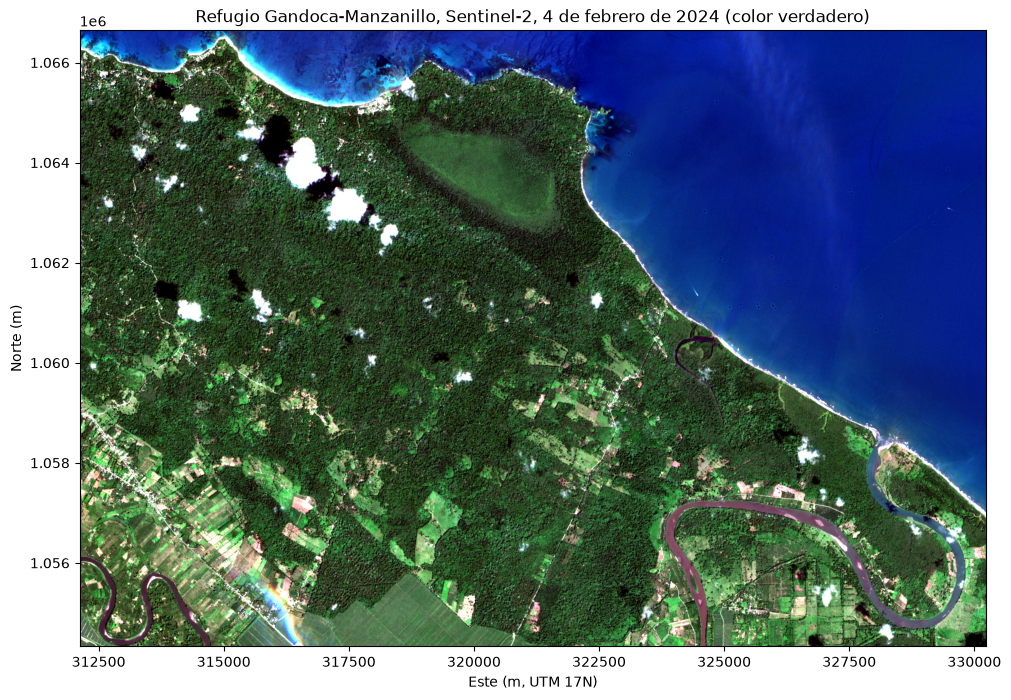

In [30]:
# Composición en color verdadero (rojo, verde, azul) con estiramiento entre los percentiles 2 y 98
def estirar(banda):
    '''Escala una banda al rango 0-1 entre sus percentiles 2 y 98.'''
    minimo, maximo = np.percentile(banda.compressed(), [2, 98])
    return np.clip((banda - minimo) / (maximo - minimo), 0, 1)

limites_gandoca = [gandoca.bounds.left, gandoca.bounds.right, gandoca.bounds.bottom, gandoca.bounds.top]
color_verdadero = np.dstack([estirar(rojo), estirar(verde), estirar(azul)])

fig, ax = plt.subplots(figsize=(12, 8))
ax.imshow(color_verdadero, extent=limites_gandoca)
ax.set_title("Refugio Gandoca-Manzanillo, Sentinel-2, 4 de febrero de 2024 (color verdadero)")
ax.set_xlabel("Este (m, UTM 17N)")
ax.set_ylabel("Norte (m)")
plt.show()

Se distinguen el mar, la costa, el bosque y las áreas abiertas. La banda infrarroja cercana no es visible, pero la vegetación sana la refleja intensamente, mucho más que la luz roja, que la clorofila absorbe. Esa diferencia es la base de la teledetección de la vegetación, y se explota de dos maneras. La primera es la composición en **falso color**: NIR en el canal rojo, rojo en el verde y verde en el azul, con la que la vegetación aparece en rojo intenso (es el ejercicio 9). La segunda es el **Índice de Vegetación de Diferencia Normalizada** (NDVI), una operación local entre las dos bandas:

$$
\text{NDVI} = \frac{\text{NIR} - \text{Rojo}}{\text{NIR} + \text{Rojo}}
$$

Toma valores entre −1 y 1: negativos en el agua, cercanos a cero en suelo desnudo y construcciones, y altos (más de 0,5) en la vegetación densa. Como operación de numpy es una línea; la condición es que las bandas sean de tipo flotante (la sección de errores muestra qué pasa si no):

NDVI mínimo: -1.0 | máximo: 1.0 | medio: 0.512


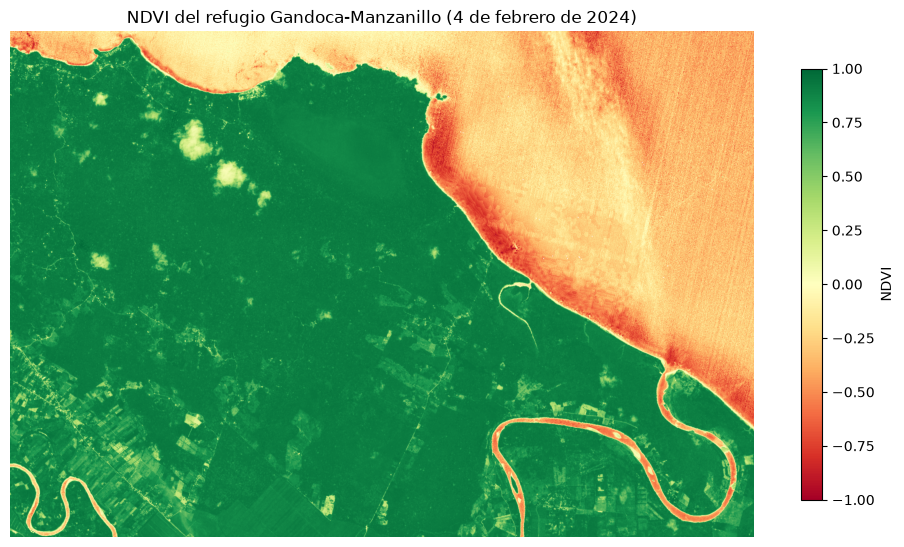

In [31]:
# NDVI: operación local entre las bandas infrarroja cercana y roja
ndvi = (nir - rojo) / (nir + rojo)

print("NDVI mínimo:", round(float(ndvi.min()), 3), "| máximo:", round(float(ndvi.max()), 3), "| medio:", round(float(ndvi.mean()), 3))

fig, ax = plt.subplots(figsize=(12, 8))
imagen = ax.imshow(ndvi, cmap="RdYlGn", extent=limites_gandoca, vmin=-1, vmax=1)
fig.colorbar(imagen, ax=ax, shrink=0.7, label="NDVI")
ax.set_title("NDVI del refugio Gandoca-Manzanillo (4 de febrero de 2024)")
ax.set_axis_off()
plt.show()

El NDVI se reclasifica como la altitud. Y como el SRC es proyectado y en metros, el área de cada clase se obtiene del número de celdas: cada una mide 100 m², es decir, 0,01 ha:

In [32]:
# Reclasificación del NDVI y área de cada clase (cada celda de 10 m × 10 m es 0,01 ha)
clases_ndvi = np.ma.masked_array(np.digitize(ndvi, [0, 0.2, 0.5]), mask=ndvi.mask)
etiquetas_ndvi = ["Agua o sin vegetación (< 0)", "Suelo desnudo o vegetación escasa (0-0,2)", "Vegetación moderada (0,2-0,5)", "Vegetación densa (> 0,5)"]

area_clases = pd.DataFrame({
    "clase": etiquetas_ndvi,
    "celdas": [(clases_ndvi == clase).sum() for clase in range(4)],
})
area_clases["hectareas"] = area_clases["celdas"] * 0.01
area_clases["porcentaje"] = (area_clases["celdas"] / clases_ndvi.count() * 100).round(1)
area_clases

,clase,celdas,hectareas,porcentaje
0,Agua o sin vegetación (< 0),659937,6599.37,29.6
1,"Suelo desnudo o vegetación escasa (0-0,2)",12674,126.74,0.6
2,"Vegetación moderada (0,2-0,5)",25521,255.21,1.1
3,"Vegetación densa (> 0,5)",1531115,15311.15,68.7


Dos tercios de la imagen son vegetación densa (bosque, manglar y humedal del refugio) y casi un tercio es agua, el mar Caribe. Un análisis real agregaría dos pasos que aquí se omiten: enmascarar las nubes (Sentinel-2 distribuye una banda de clasificación de escena para eso) y recortar al polígono del refugio con `mask()`, como se hizo con Brasil.

*Ejercicios de esta sección: 9 y 10, en la sección de ejercicios al final del cuaderno.*

## Escritura de un raster

Un resultado como el NDVI se guarda en un GeoTIFF nuevo con `rasterio.open()` en modo de escritura (`"w"`). Hace falta el encabezado completo, y la forma habitual de construirlo es copiar el **perfil** de la imagen de origen (mismas dimensiones, SRC y transformación) y cambiar lo que difiere: una banda en lugar de cuatro, tipo flotante, un valor sin dato apropiado y, opcionalmente, compresión. Las celdas enmascaradas se rellenan con ese valor antes de escribir:

In [33]:
# Escritura del NDVI como GeoTIFF: perfil de la imagen de origen con los cambios necesarios
perfil = gandoca.profile.copy()
perfil.update(count=1, dtype="float32", nodata=-9999, compress="deflate")

with rasterio.open("gandoca-ndvi.tif", "w", **perfil) as destino:
    destino.write(ndvi.filled(-9999).astype("float32"), 1)
    destino.set_band_description(1, "NDVI")

# Comprobación: el archivo se reabre y conserva la georreferenciación
with rasterio.open("gandoca-ndvi.tif") as ndvi_tif:
    print(ndvi_tif.profile)
    print("Descripción:", ndvi_tif.descriptions)
    print("NDVI medio releído:", round(float(ndvi_tif.read(1, masked=True).mean()), 3))

{'driver': 'GTiff', 'dtype': 'float32', 'nodata': -9999.0, 'width': 1811, 'height': 1231, 'count': 1, 'crs': CRS.from_wkt('PROJCS["WGS 84 / UTM zone 17N",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",-81],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","32617"]]'), 'transform': Affine(10.0, 0.0, 312120.0,
       0.0, -10.0, 1066640.0), 'blockxsize': 1811, 'blockysize': 2, 'tiled': False, 'compress': 'deflate', 'interleave': 'band'}
Descripción: ('NDVI',)
NDVI medio releído: 0.512


El archivo `gandoca-ndvi.tif` queda en el directorio de trabajo y puede abrirse en QGIS: tiene el SRC y la transformación de la imagen original. El bloque `with` es obligatorio aquí (o `close()` explícito): el archivo se escribe en disco al cerrarse. Para rasters que se publicarán en Internet conviene el formato [GeoTIFF optimizado para la nube](https://cogeo.org/) (COG), un GeoTIFF organizado en bloques con vistas previas, que permite a GDAL leer solo la ventana necesaria; se crea con el controlador `"COG"` en lugar de `"GTiff"`.

*Ejercicios de esta sección: 11, en la sección de ejercicios al final del cuaderno.*

## Reproyección

Reproyectar un raster es más delicado que reproyectar una capa vectorial: no basta con transformar coordenadas, hay que construir una **cuadrícula nueva** en el SRC de destino y calcular el valor de cada celda nueva a partir de las antiguas, un proceso llamado **remuestreo**. El módulo `rasterio.warp` lo hace en dos pasos: `calculate_default_transform()` calcula la transformación y las dimensiones de la cuadrícula de destino, y `reproject()` rellena un array vacío con los valores remuestreados. La altitud mundial en Equal Earth (EPSG:8857):

Cuadrícula de destino: 1533 filas x 3150 columnas | resolución: 10947 m


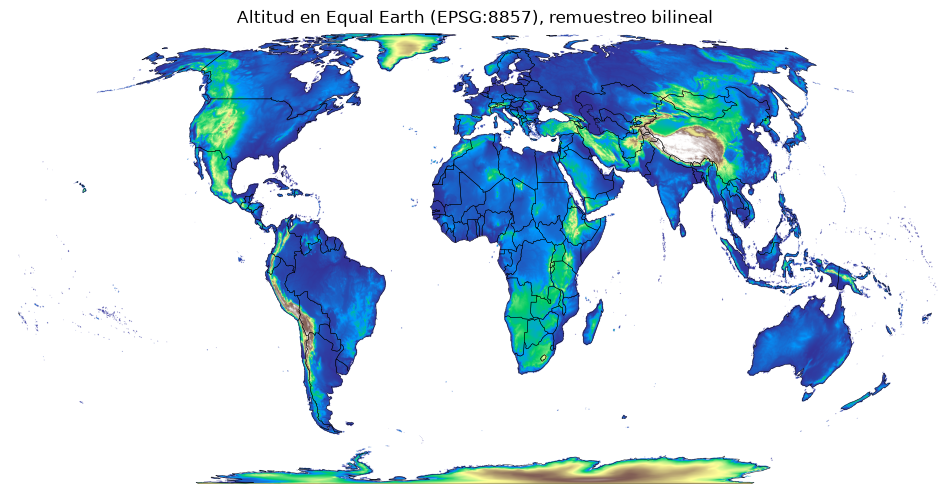

In [34]:
# Reproyección de la altitud a Equal Earth: cuadrícula de destino y remuestreo
from rasterio.warp import calculate_default_transform, reproject, Resampling

transformacion_ee, ancho_ee, alto_ee = calculate_default_transform(altitud.crs, "EPSG:8857", altitud.width, altitud.height, *altitud.bounds)
print("Cuadrícula de destino:", alto_ee, "filas x", ancho_ee, "columnas | resolución:", round(transformacion_ee.a), "m")

altitud_ee = np.full((alto_ee, ancho_ee), altitud.nodata, dtype="int16")
with rasterio.Env(CHECK_WITH_INVERT_PROJ=True):  # deja vacías las celdas fuera del contorno del globo
    reproject(
        source=altitud.read(1), destination=altitud_ee,
        src_transform=altitud.transform, src_crs=altitud.crs, src_nodata=altitud.nodata,
        dst_transform=transformacion_ee, dst_crs="EPSG:8857", dst_nodata=altitud.nodata,
        resampling=Resampling.bilinear,
    )
altitud_ee = np.ma.masked_equal(altitud_ee, altitud.nodata)

fig, ax = plt.subplots(figsize=(12, 6))
show(altitud_ee, transform=transformacion_ee, ax=ax, cmap="terrain", vmin=0, vmax=5000)
paises.to_crs(8857).boundary.plot(ax=ax, color="black", linewidth=0.3)
ax.set_title("Altitud en Equal Earth (EPSG:8857), remuestreo bilineal")
ax.set_axis_off()
plt.show()

El array de destino se crea lleno del valor sin dato y `reproject()` lo rellena. La opción `CHECK_WITH_INVERT_PROJ` de GDAL (fijada con `rasterio.Env`) hace falta en las proyecciones mundiales como Equal Earth, cuyo contorno no es rectangular: sin ella, GDAL rellena las esquinas fuera del globo con datos repetidos de los bordes.

El **método de remuestreo** depende del tipo de dato: `bilinear` (o `cubic`) promedia las celdas vecinas y es adecuado para variables continuas como la altitud; `nearest` toma el valor de la celda más cercana y es el único correcto para rasters **categóricos** (los pisos altitudinales, una cobertura de la tierra), porque promediar clases produce clases inexistentes. Para reducir la resolución, `average` promedia todas las celdas de origen que caen en cada celda de destino.

La reproyección resuelve la advertencia sobre el conteo de celdas: en Equal Earth cada celda mide lo mismo (unos 11 km de lado, 120 km²), así que contar celdas sí equivale a medir superficie. La proporción de tierra firme por encima de 1 000 m, calculada en las dos cuadrículas:

In [35]:
# Proporción de tierra firme por encima de 1 000 m: contar celdas en grados exagera las latitudes altas
proporcion_wgs84 = (altitud_m > 1000).sum() / altitud_m.count() * 100
proporcion_ee = (altitud_ee > 1000).sum() / altitud_ee.count() * 100

print(f"En la cuadrícula en grados (WGS84): {proporcion_wgs84:.1f} % de las celdas")
print(f"En la cuadrícula de igual área (Equal Earth): {proporcion_ee:.1f} % de la superficie")
print(f"Superficie total con dato en Equal Earth: {altitud_ee.count() * 120 / 1e6:.0f} millones de km²")

En la cuadrícula en grados (WGS84): 37.6 % de las celdas
En la cuadrícula de igual área (Equal Earth): 24.8 % de la superficie
Superficie total con dato en Equal Earth: 155 millones de km²


La diferencia la explica la Antártida: una meseta de hielo de más de 2 000 m de altitud media que ocupa el 27 % de las celdas en grados (cerca del polo, los grados de longitud son diminutos) pero solo el 8 % de la superficie terrestre. Es la misma lección de la lección 16 y el cuaderno de geopandas I, ahora con rasters: para medir, un SRC de igual área.

*Ejercicios de esta sección: 12, en la sección de ejercicios al final del cuaderno.*

## Clínica de errores

Los errores propios de los datos raster, provocados a propósito. Los dos primeros son los más peligrosos, porque no detienen el programa: producen un resultado incorrecto en silencio.

In [36]:
# Error silencioso 1: estadísticas sin enmascarar el valor sin dato
# El océano vale -32768 y numpy lo promedia como si fuera una altitud. Solución: read(..., masked=True).
sin_mascara = altitud.read(1)
print("Media sin máscara:", round(float(sin_mascara.mean())), "m | media con máscara:", round(float(altitud_m.mean())), "m")

Media sin máscara: -21041 m | media con máscara: 1089 m


In [37]:
# Error silencioso 2: aritmética con enteros sin signo
# Las bandas de Sentinel-2 son uint16: una resta que da negativo "da la vuelta" y produce valores enormes
# (65 535 en lugar de -1), y el NDVI resulta absurdo. Solución: astype("float32") antes de operar.
nir_entero, rojo_entero = gandoca.read(4), gandoca.read(3)
diferencia = nir_entero - rojo_entero
print("Tipo:", diferencia.dtype, "| máximo de NIR - Rojo:", diferencia.max(), "| con flotantes:", (nir_entero.astype("float32") - rojo_entero).max())

Tipo: uint16 | máximo de NIR - Rojo: 65535 | con flotantes: 7900.0


In [38]:
# Error silencioso 3: coordenadas en orden (latitud, longitud)
# index() y sample() esperan (x, y) = (longitud, latitud). Invertidas, San José cae en la Antártida
# (longitud 9,93, latitud -84,08), que sí existe en un raster mundial: no hay error, solo un valor absurdo.
fila_mal, columna_mal = altitud.index(9.93, -84.08)
print("Celda:", (fila_mal, columna_mal), "| centro:", tuple(round(c, 4) for c in altitud.xy(fila_mal, columna_mal)), "| altitud:", altitud_m[fila_mal, columna_mal], "m")

Celda: (1044, 1139) | centro: (np.float64(9.9167), np.float64(-84.0833)) | altitud: 2571 m


In [39]:
# ValueError: "Input shapes do not overlap raster."
# Las geometrías de mask() deben estar en el SRC del raster: Brasil en Equal Earth (metros) no se
# superpone con un raster en grados. Solución: brasil.to_crs(altitud.crs) o brasil.geometry sin reproyectar.
mask(altitud, brasil.to_crs(8857).geometry, crop=True)

ValueError: Input shapes do not overlap raster.

In [40]:
# IndexError: "band index 0 out of range (not in (1,))"
# Las bandas de rasterio se numeran desde 1, no desde 0 como los índices de Python.
altitud.read(0)

IndexError: band index 0 out of range (not in (1,))

In [41]:
# RasterioIOError: "Dataset is closed"
# Un conjunto de datos cerrado (al salir de un bloque with o con close()) ya no puede leerse.
with rasterio.open(f"{DATOS_WC}/precipitacion.tif") as temporal:
    pass
temporal.read(1)

RasterioIOError: Dataset is closed: https://raw.githubusercontent.com/gf0657-programacionsig/2026-ii/main/datos/worldclim/precipitacion.tif

## Asistentes de IA para procesar datos raster

Las pautas de los cuadernos anteriores aplican: describir los datos en el contexto (dimensiones, tipo de dato, SRC y valor sin dato de cada raster; SRC de las capas vectoriales), pedir el patrón del curso y verificar el resultado. Para los rasters, las comprobaciones son cuatro: que el valor sin dato esté **enmascarado** en todo cálculo; que los **tipos de dato** sean los adecuados (flotante antes de dividir o restar enteros sin signo); que raster y vector estén en el **mismo SRC**, y que ese SRC sea de igual área si se cuentan celdas; y que un resultado conocido sea correcto (la altitud media de Nepal ronda los 2 000 m a esta resolución; el NDVI del bosque supera 0,5). Un prompt de ejemplo:

> Actúe como asistente de procesamiento de datos geoespaciales con rasterio y numpy **(rol)**. Tengo un raster `precipitacion` abierto con rasterio (una banda `int16` de 1 080 × 2 160 celdas en EPSG:4326, con −32 768 como valor sin dato, precipitación anual en mm) y un GeoDataFrame `paises` en EPSG:4326 con 177 polígonos y las columnas `codigo` y `nombre` **(contexto)**. Escriba el código que calcule, para cada país, la precipitación anual media y máxima de sus celdas, agregue las dos columnas a `paises` (con NaN para los países sin celdas) y muestre los diez países más lluviosos **(tarea)**. Use `rasterio.mask.mask()` con `crop=True`, enmascare el valor sin dato con `numpy.ma`, construya un DataFrame y únalo con `merge()`, y agregue un comentario por paso **(formato)**.

## Resumen

- Un raster es **una matriz de numpy más un encabezado**: `rasterio.open()` lee el encabezado (`count`, `shape`, `dtypes`, `crs`, `res`, `bounds`, `nodata`, `transform`, `profile`) y `read()` entrega la matriz. Las bandas se numeran desde 1.
- El **valor sin dato** marca las celdas vacías con un número cualquiera del tipo de dato: se lee con `masked=True` para excluirlo de todo cálculo. Las estadísticas, comparaciones e histogramas son operaciones de numpy sobre el array enmascarado.
- La **transformación afín** relaciona índices (fila, columna) con coordenadas (x, y): `index()` y `xy()` convierten en cada dirección, y `sample()` consulta el valor de muchos puntos, que deben estar en el SRC del raster. Una **ventana** lee solo una parte del raster, incluso remoto.
- Los mapas se dibujan con `show()` o con `imshow()` más `extent`, con paletas secuenciales o divergentes según la variable, `vmin`/`vmax` para fijar la escala y, para rasters categóricos, una paleta discreta sin interpolación. Las capas vectoriales se superponen en el mismo SRC.
- El **álgebra de mapas** local es aritmética y lógica entre arrays alineados; `np.digitize()` **reclasifica** un raster continuo en categorías.
- `rasterio.mask.mask()` **recorta y enmascara** un raster con geometrías en su SRC, y repetido por polígono produce **estadísticas zonales**, que se unen a la capa vectorial como atributos nuevos.
- Una imagen de satélite es un raster **multibanda**: `read()` retorna (banda, fila, columna); las bandas se convierten a reflectancia, se combinan en **composiciones de color** (`np.dstack()` con estiramiento) y en índices como el **NDVI**, en flotante.
- Se **escribe** un GeoTIFF con el perfil de origen modificado, en un bloque `with`; se **reproyecta** con `calculate_default_transform()` y `reproject()`, con remuestreo bilineal para variables continuas y `nearest` para categóricas. Contar celdas mide superficie solo en un SRC de igual área.

## Ejercicios

Los ejercicios se agrupan según la sección del cuaderno a la que corresponden; se recomienda realizarlos al concluir la sección respectiva. Resuélvalos en este mismo cuaderno (en su copia de Colab o local), después de ejecutar las celdas de las secciones anteriores. Varios incluyen una **celda de verificación** que examina el objeto creado: para que funcione, nombre los objetos como se indica en el enunciado y ejecute la celda tal cual después de resolver el ejercicio (en la versión publicada muestra un recordatorio, porque los ejercicios no están resueltos). Las [soluciones de estos ejercicios](https://gf0657-programacionsig.github.io/2026-ii/soluciones-rasterio-datos-raster) se publican después de la clase correspondiente.

### Apertura y metadatos

1. La variable `precipitacion` ya está abierta. Muestre, en una celda, sus bandas, dimensiones, tipo de dato, SRC, resolución, límites y valor sin dato, y compruebe con una expresión booleana que su transformación afín es **idéntica** a la de `altitud`, en `alineadas`. ¿Por qué importa esa igualdad para el álgebra de mapas?

In [42]:
# Celda de verificación del ejercicio 1: ejecútela tal cual
try:
    assert alineadas is True or alineadas is np.True_, "alineadas debe ser el resultado (True) de comparar las dos transformaciones"
    assert precipitacion.dtypes[0] == "int16" and precipitacion.nodata == -32768, "La precipitación es int16 con -32768 como valor sin dato"
    print("Ejercicio 1: ¡correcto!")
except NameError:
    print("Aún no se ha definido alineadas (ejercicio 1).")

Aún no se ha definido alineadas (ejercicio 1).


### La matriz de celdas

2. Con `precipitacion_m` (ya leída con máscara), calcule la precipitación mínima, máxima, media y mediana de las celdas terrestres, y guarde en `muy_lluviosas` la máscara booleana de las celdas con más de 3 000 mm. ¿Qué porcentaje de las celdas terrestres son? Localice la celda de precipitación máxima con `np.argmax()` y `np.unravel_index()`, obtenga sus coordenadas con `xy()` y busque el lugar en un mapa: ¿qué es? ¿Le parece un valor confiable?

In [43]:
# Celda de verificación del ejercicio 2: ejecútela tal cual
try:
    assert muy_lluviosas.dtype == bool and muy_lluviosas.shape == precipitacion_m.shape, "muy_lluviosas debe ser una máscara booleana del tamaño del raster"
    assert muy_lluviosas.sum() == 8774, "Hay 8 774 celdas con más de 3 000 mm"
    print("Ejercicio 2: ¡correcto!")
except NameError:
    print("Aún no se ha definido muy_lluviosas (ejercicio 2).")

Aún no se ha definido muy_lluviosas (ejercicio 2).


### Graficación

3. Dibuje en `ax_3` el mapa mundial de la precipitación anual con `imshow()`: paleta `Blues`, escala de 0 a 4 000 mm, límites de los países encima, barra de color con etiqueta, título y sin ejes. ¿Dónde están las franjas más lluviosas y las más secas? Relaciónelas con la circulación atmosférica (zona de convergencia intertropical, desiertos subtropicales).

In [44]:
# Celda de verificación del ejercicio 3: ejecútela tal cual
try:
    assert len(ax_3.images) >= 1 and ax_3.images[0].get_cmap().name == "Blues", "Falta la imagen o la paleta no es Blues"
    assert ax_3.get_title() and not ax_3.axison, "Falta el título o los ejes siguen visibles"
    assert len(ax_3.collections) >= 1, "Faltan los límites de los países"
    print("Ejercicio 3: ¡correcto!")
except NameError:
    print("Aún no se ha definido ax_3 (ejercicio 3).")

Aún no se ha definido ax_3 (ejercicio 3).


### Celdas y coordenadas

4. Filtre las capitales de los siete países de Centroamérica en `capitales_ca` (por `codigo_pais`) y agregue dos columnas con su altitud muestreada en la capa mundial (`altitud_10`) y en la regional (`altitud_2_5`), más la diferencia entre ambas. ¿En qué capital difieren más y por qué? Pista: piense en el tamaño de la celda y en el relieve que la rodea.

In [45]:
# Celda de verificación del ejercicio 4: ejecútela tal cual
try:
    assert len(capitales_ca) == 7 and {"altitud_10", "altitud_2_5"} <= set(capitales_ca.columns), "Deben ser las 7 capitales con las columnas altitud_10 y altitud_2_5"
    assert capitales_ca.set_index("nombre").loc["Managua", "altitud_10"] - capitales_ca.set_index("nombre").loc["Managua", "altitud_2_5"] > 150, "Managua difiere en más de 150 m"
    print("Ejercicio 4: ¡correcto!")
except NameError:
    print("Aún no se ha definido capitales_ca (ejercicio 4).")

Aún no se ha definido capitales_ca (ejercicio 4).


### Álgebra de mapas

5. Reclasifique la precipitación anual en cuatro clases en `clases_prec` (array enmascarado de enteros): menos de 250 mm (árido), 250-1 000 (seco), 1 000-2 000 (húmedo) y más de 2 000 (muy húmedo). Cuente las celdas de cada clase y dibuje el raster categórico en `ax_5` con una paleta discreta, leyenda con parches, límites de países, título y sin ejes.

In [46]:
# Celda de verificación del ejercicio 5: ejecútela tal cual
try:
    assert clases_prec.shape == precipitacion_m.shape and set(np.unique(clases_prec.compressed())) <= {0, 1, 2, 3}, "clases_prec debe tener cuatro clases (0 a 3) y la forma del raster"
    assert (clases_prec == 0).sum() == 329230, "Hay 329 230 celdas áridas (menos de 250 mm)"
    assert ax_5.get_legend() is not None and not ax_5.axison, "Falta la leyenda o los ejes siguen visibles"
    print("Ejercicio 5: ¡correcto!")
except NameError:
    print("Aún no se han definido clases_prec y ax_5 (ejercicio 5).")

Aún no se han definido clases_prec y ax_5 (ejercicio 5).


6. Guarde en `frio_seco` la máscara booleana de las celdas con temperatura media por debajo de 0 °C y precipitación por debajo de 250 mm, y calcule qué porcentaje de las celdas terrestres son y su altitud media. ¿Dónde se concentran (dibújelas si lo necesita)? ¿Cuánto de ese porcentaje cree que se debe a la Antártida y por qué el porcentaje de celdas exagera su peso?

In [47]:
# Celda de verificación del ejercicio 6: ejecútela tal cual
try:
    assert frio_seco.dtype == bool and frio_seco.shape == temperatura_m.shape, "frio_seco debe ser una máscara booleana del tamaño del raster"
    assert frio_seco.sum() == 239782, "Hay 239 782 celdas frías y secas"
    print("Ejercicio 6: ¡correcto!")
except NameError:
    print("Aún no se ha definido frio_seco (ejercicio 6).")

Aún no se ha definido frio_seco (ejercicio 6).


### Raster y vector

7. Recorte la altitud con el polígono de Chile en `altitud_chile` (array enmascarado) y su transformación en `transformacion_chile`, calcule la altitud media y máxima, y dibuje el recorte en `ax_7` con `show()`, el contorno del país encima, título y sin ejes. ¿Por qué la altitud media de Chile es tan alta si la mayor parte de su población vive cerca del nivel del mar?

In [48]:
# Celda de verificación del ejercicio 7: ejecútela tal cual
try:
    assert isinstance(altitud_chile, np.ma.MaskedArray) and altitud_chile.max() == 5455, "La celda más alta de Chile mide 5 455 m"
    assert 1000 < altitud_chile.mean() < 1100, "La altitud media de Chile ronda los 1 050 m"
    assert ax_7.get_title() and not ax_7.axison, "Falta el título o los ejes siguen visibles"
    print("Ejercicio 7: ¡correcto!")
except NameError:
    print("Aún no se han definido altitud_chile y ax_7 (ejercicio 7).")

Aún no se han definido altitud_chile y ax_7 (ejercicio 7).


8. `paises_clima` ya tiene la precipitación media por país. Muestre los diez países más lluviosos y los diez más secos, y dibuje en `ax_8` un mapa de coropletas en Equal Earth de la precipitación media, clasificado en cuantiles, con leyenda, título y sin ejes. Guarde en `mas_lluvioso` el nombre del país con mayor precipitación media. ¿Es el resultado consistente con el mapa del ejercicio 3?

In [49]:
# Celda de verificación del ejercicio 8: ejecútela tal cual
try:
    assert mas_lluvioso == "Brunéi", "El país más lluvioso en promedio es Brunéi"
    assert ax_8.get_legend() is not None and ax_8.get_title() and not ax_8.axison, "Falta la leyenda, el título o los ejes siguen visibles"
    print("Ejercicio 8: ¡correcto!")
except NameError:
    print("Aún no se han definido mas_lluvioso y ax_8 (ejercicio 8).")

Aún no se han definido mas_lluvioso y ax_8 (ejercicio 8).


### Múltiples bandas

9. Construya en `falso_color` la composición en falso color de la imagen de Gandoca (NIR en el canal rojo, rojo en el verde y verde en el azul, estiradas con `estirar()`) y dibújela en `ax_9` con `extent`, título y sin ejes. ¿De qué color aparece la vegetación y por qué? ¿Qué elementos se distinguen mejor que en color verdadero?

In [50]:
# Celda de verificación del ejercicio 9: ejecútela tal cual
try:
    assert falso_color.shape == (gandoca.height, gandoca.width, 3), "falso_color debe tener la forma (filas, columnas, 3)"
    assert float(falso_color[..., 0].mean()) > float(falso_color[..., 1].mean()), "El canal rojo (NIR) debe dominar sobre la vegetación"
    assert ax_9.get_title() and not ax_9.axison, "Falta el título o los ejes siguen visibles"
    print("Ejercicio 9: ¡correcto!")
except NameError:
    print("Aún no se han definido falso_color y ax_9 (ejercicio 9).")

Aún no se han definido falso_color y ax_9 (ejercicio 9).


10. Calcule el [Índice de Agua de Diferencia Normalizada](https://en.wikipedia.org/wiki/Normalized_difference_water_index) (NDWI) de McFeeters, `(Verde − NIR) / (Verde + NIR)`, en `ndwi`, dibújelo con una paleta divergente y guarde en `area_agua_ha` el área en hectáreas de las celdas con NDWI mayor que 0. Compárela con el área de la clase "Agua o sin vegetación" del NDVI: ¿coinciden? ¿Cuál índice separa mejor el agua?

In [51]:
# Celda de verificación del ejercicio 10: ejecútela tal cual
try:
    assert ndwi.shape == ndvi.shape and -1 <= float(ndwi.min()) and float(ndwi.max()) <= 1, "ndwi debe tener la forma de la imagen y valores entre -1 y 1"
    assert 6000 < area_agua_ha < 7000, "El agua ocupa entre 6 000 y 7 000 ha"
    print("Ejercicio 10: ¡correcto!")
except NameError:
    print("Aún no se han definido ndwi y area_agua_ha (ejercicio 10).")

Aún no se han definido ndwi y area_agua_ha (ejercicio 10).


### Escritura

11. Escriba el raster de pisos altitudinales `pisos` en el archivo `pisos-altitudinales.tif`, como una banda de tipo `uint8` con 255 como valor sin dato y compresión, a partir del perfil de `altitud`. Reábralo en `pisos_tif` y compruebe que conserva el SRC y la transformación de la altitud y que sus valores son solo 0, 1, 2, 3 y 255.

In [52]:
# Celda de verificación del ejercicio 11: ejecútela tal cual
try:
    assert pisos_tif.dtypes[0] == "uint8" and pisos_tif.nodata == 255 and pisos_tif.count == 1, "Debe ser una banda uint8 con 255 como valor sin dato"
    assert pisos_tif.crs == altitud.crs and pisos_tif.transform == altitud.transform, "Debe conservar el SRC y la transformación de la altitud"
    assert set(np.unique(pisos_tif.read(1))) <= {0, 1, 2, 3, 255}, "Los valores deben ser 0 a 3 y 255"
    print("Ejercicio 11: ¡correcto!")
except NameError:
    print("Aún no se ha definido pisos_tif (ejercicio 11).")

Aún no se ha definido pisos_tif (ejercicio 11).


### Reproyección

12. Reproyecte el raster categórico `pisos` a Equal Earth en `pisos_ee` (array enmascarado, con la transformación de destino y la opción `CHECK_WITH_INVERT_PROJ` como en la sección) con el método de remuestreo **adecuado para categorías**, y compare el porcentaje de la tierra firme en el piso altoandino (clase 3) contado en grados y en Equal Earth. ¿Qué pasaría con `Resampling.bilinear`? Pruébelo y cuente los valores únicos.

In [53]:
# Celda de verificación del ejercicio 12: ejecútela tal cual
try:
    assert pisos_ee.shape == (alto_ee, ancho_ee), "pisos_ee debe tener la forma de la cuadrícula de Equal Earth"
    assert set(np.unique(pisos_ee.compressed())) <= {0, 1, 2, 3}, "Con remuestreo nearest solo hay cuatro clases"
    print("Ejercicio 12: ¡correcto!")
except NameError:
    print("Aún no se ha definido pisos_ee (ejercicio 12).")

Aún no se ha definido pisos_ee (ejercicio 12).


### Predicción, asistentes y tarea 3

13. **Prediga antes de ejecutar**: ¿qué imprime cada línea y por qué? Escriba su predicción en una celda de texto y luego ejecútelas. Pista: la figura 1 y los atributos `transform`, `shape` y `bounds` de `altitud`.

```python
print(altitud.index(-180, 90))
print(altitud.index(0, 0))
print(altitud.xy(0, 0))
print(altitud.transform * (2160, 1080))
```

<details>
<summary>Explicación (ábrala después de predecir)</summary>

`(0, 0)`: la esquina superior izquierda del mundo es la primera celda. `(540, 1080)`: el punto (0, 0) está a 90° del borde superior y a 180° del izquierdo, y a 1/6 de grado por celda son 540 filas y 1 080 columnas. `(-179.9167, 89.9167)`: el centro de la primera celda, medio paso (1/12 de grado) hacia adentro desde el origen. `(180.0, -90.0)`: la esquina inferior derecha de la última celda, es decir, el extremo opuesto de los límites.

</details>

14. Pida a un asistente de IA el código del prompt de ejemplo de la sección de asistentes (precipitación media y máxima por país) y verifíquelo con las cuatro comprobaciones de esa sección: valor sin dato enmascarado, tipos de dato, mismo SRC y un resultado conocido (compare la media con la columna `precipitacion_media` de `paises_clima`). Documente en una celda de texto el asistente, el prompt, el código y el resultado de las comprobaciones.

15. Para la tarea 3, identifique un raster relacionado con su tema: altitud ([Copernicus DEM](https://dataspace.copernicus.eu/explore-data/data-collections/copernicus-contributing-missions/collections-description/COP-DEM) o [SRTM](https://www.earthdata.nasa.gov/data/instruments/srtm)), clima ([WorldClim](https://www.worldclim.org/) o [CHIRPS](https://www.chc.ucsb.edu/data/chirps)), cobertura de la tierra ([ESA WorldCover](https://esa-worldcover.org/)), imágenes ([Sentinel-2](https://dataspace.copernicus.eu/) o [Landsat](https://www.usgs.gov/landsat-missions)) o cualquier otro. Ábralo con rasterio, documente en una celda de texto sus metadatos (bandas, resolución, SRC, valor sin dato, fuente y fecha) y calcule una estadística zonal o un recorte con la capa vectorial de su tema. Anote qué pregunta de su tema responde.

## Referencias bibliográficas

Dorman, M., Graser, A., Nowosad, J. y Lovelace, R. (2025). *Geocomputation with Python*. CRC Press. https://py.geocompx.org/
\
\
Fick, S. E. y Hijmans, R. J. (2017). WorldClim 2: New 1-km spatial resolution climate surfaces for global land areas. *International Journal of Climatology, 37*(12), 4302–4315. [https://rmets.onlinelibrary.wiley.com/doi/10.1002/joc.5086](https://rmets.onlinelibrary.wiley.com/doi/10.1002%2Fjoc.5086)
\
\
Harris, C. R., Millman, K. J., van der Walt, S. J., Gommers, R., Virtanen, P., Cournapeau, D., Wieser, E., Taylor, J., Berg, S., Smith, N. J., Kern, R., Picus, M., Hoyer, S., van Kerkwijk, M. H., Brett, M., Haldane, A., Fernández del Río, J., Wiebe, M., Peterson, P., … Oliphant, T. E. (2020). Array programming with NumPy. *Nature, 585*, 357–362. [https://www.nature.com/articles/s41586-020-2649-2](https://www.nature.com/articles/s41586-020-2649-2)
\
\
Microsoft. (s. f.). *Sentinel-2 Level-2A*. Microsoft Planetary Computer. Recuperado el 18 de octubre de 2026, de https://planetarycomputer.microsoft.com/dataset/sentinel-2-l2a
\
\
Natural Earth. (s. f.). *Natural Earth: Free vector and raster map data* [Conjunto de datos]. Recuperado el 4 de octubre de 2026, de https://www.naturalearthdata.com/
\
\
Rasterio Contributors. (s. f.). *Rasterio: Access to geospatial raster data*. Recuperado el 18 de octubre de 2026, de https://rasterio.readthedocs.io/
\
\
WorldClim. (s. f.). *WorldClim version 2.1* [Conjunto de datos]. Recuperado el 18 de octubre de 2026, de https://www.worldclim.org/data/worldclim21.html